# 02 · EDA: NBA player points

**Goal (Phase 2):** understand the data before building features. Questions:
- What does the distribution of points look like?
- How strongly do points depend on minutes?
- Home vs away scoring; back-to-back vs rested.
- How much does a player's scoring vary from game to game? (The standard deviation matters for Phase 8.)

Input: `nba/data/processed/games.parquet` from `01_data.ipynb` (one row per player per game, 0-minute rows removed).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from fbml.config import ROOT

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

games = pd.read_parquet(ROOT / "nba" / "data" / "processed" / "games.parquet")
print(games.shape)
games.head()

(130830, 13)


,season,player_id,player,team,opponent,game_id,date,home,minutes,points,fga,fg3a,fta
0,22021,2544,LeBron James,LAL,GSW,0022100002,2021-10-19,1,37,34,23,11,6
1,22021,2546,Carmelo Anthony,LAL,GSW,0022100002,2021-10-19,1,26,9,9,4,2
2,22021,2730,Dwight Howard,LAL,GSW,0022100002,2021-10-19,1,13,5,2,0,4
3,22021,2738,Andre Iguodala,GSW,LAL,0022100002,2021-10-19,0,23,12,7,5,2
4,22021,200746,LaMarcus Aldridge,BKN,MIL,0022100001,2021-10-19,0,16,1,2,0,4


In [ ]:
zero_pts = games['points'] == 0
print("share of 0-point games:", round(zero_pts.mean(), 3))

games['points'].describe()

In [ ]:
sns.histplot(games['points'], edgecolor='black', discrete=True);

**Step 1 findings: points distribution**
- Mean 10.7 > median 9, so the distribution is **right-skewed**: most games are low-scoring, with a long tail of big nights (max 83).
- About 11% of player-games end with 0 points (mostly short bench minutes).
- So points are **not** a bell curve. A normal distribution centred on the mean would misprice overs and unders, so Phase 8 needs a skew-friendly distribution, built per player.

np.float64(0.7373166185627951)

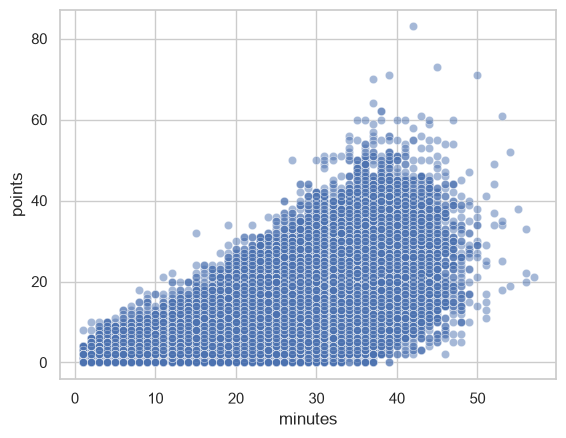

In [6]:
sns.scatterplot(data=games, x='minutes', y='points', alpha=0.05, s=5);
print('corr:', round(games['minutes'].corr(games['points']), 3))

**Step 2 findings: points vs minutes**
- Correlation 0.74: more minutes, more points. Predicting minutes well is half the job.
- The spread of points grows with minutes (std about 2 at 0–10 min, about 10 at 40+): a funnel, i.e. heteroscedasticity. Phase 8 needs a per-player spread, not one fixed std for everyone.

In [ ]:
# home: 0 = away, 1 = home
games.groupby('home')[['points', 'minutes']].mean()

In [ ]:
# days since this player's previous game; NaN for each player's first game
games['rest_days'] = games.groupby('player_id')['date'].diff().dt.days

# cap long gaps (injuries, off-season) at 4 so they form one '4+' group
rest = games['rest_days'].clip(upper=4)

summary = games.groupby(rest)[['points', 'minutes']].mean().round(2)
summary['games'] = rest.value_counts().sort_index()
summary

1029 players, 494 with 100+ games
corr(mean, std): 0.818


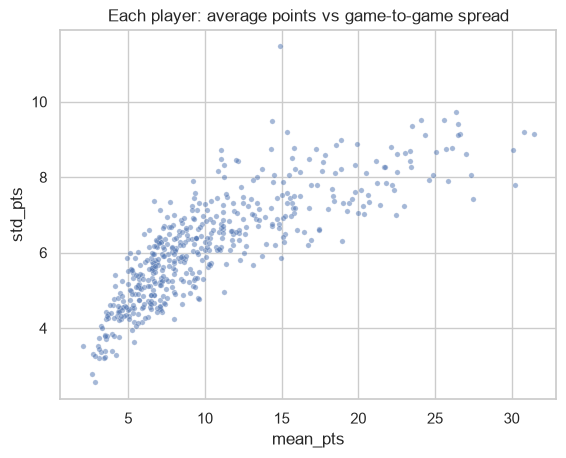

In [13]:
# one row per player: games played, name, mean and std of points
per_player = games.groupby('player_id').agg(
    games=('player_id', 'count'),
    player=('player', 'first'),
    mean_pts=('points', 'mean'),
    std_pts=('points', 'std'),
)

# a std from a handful of games is noise, so keep players with 100+ games
regulars = per_player[per_player['games'] >= 100]
print(len(per_player), "players,", len(regulars), "with 100+ games")
print("corr(mean, std):", round(regulars['mean_pts'].corr(regulars['std_pts']), 3))

sns.scatterplot(data=regulars, x='mean_pts', y='std_pts', alpha=0.5, s=15)
plt.title('Each player: average points vs game-to-game spread');

In [14]:
# among 20+ point scorers: lowest std = most consistent, highest = most volatile
scorers = regulars[regulars['mean_pts'] >= 20].sort_values('std_pts')
cols = ['player', 'games', 'mean_pts', 'std_pts']

print("Most consistent:")
print(scorers[cols].head(5).round(1).to_string(index=False))
print()
print("Most volatile:")
print(scorers[cols].tail(5).round(1).to_string(index=False))

Most consistent:
            player  games  mean_pts  std_pts
     Pascal Siakam    359      22.5      7.0
Kristaps Porziņģis    247      20.4      7.0
        RJ Barrett    316      20.0      7.0
   Zion Williamson    191      23.0      7.2
    Darius Garland    314      20.3      7.2

Most volatile:
         player  games  mean_pts  std_pts
   Tyrese Maxey    327      23.5      9.4
 Damian Lillard    218      26.5      9.4
Anthony Edwards    370      25.6      9.5
  Jalen Brunson    363      24.1      9.5
  Stephen Curry    307      26.4      9.7
